<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta8g%C3%B6rev6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

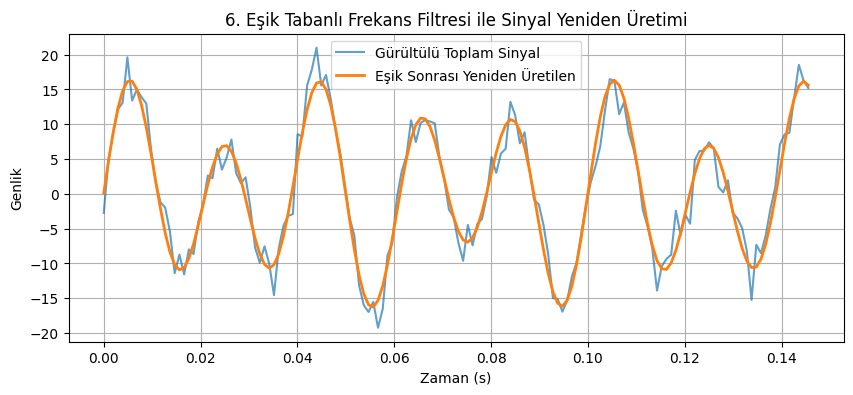

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def harmonik_esik_filtre(sinyal, esik_deger):
    harmonik = np.fft.fft(sinyal)
    filtreli_harmonik = np.where(np.abs(harmonik) >= esik_deger, harmonik, 0.0)
    yeniden_sinyal = np.real(np.fft.ifft(filtreli_harmonik))
    return yeniden_sinyal, filtreli_harmonik


N = 1024
fs = 1024.0
t = np.arange(N) / fs
rng = np.random.default_rng(99)

s1 = 12.0 * np.sin(2 * np.pi * 50.0 * t) + rng.normal(0, 1.5, size=N)
s2 = 5.0 * np.sin(2 * np.pi * 30.0 * t) + rng.normal(0, 1.5, size=N)
toplam = s1 + s2

yeniden_toplam, _ = harmonik_esik_filtre(toplam, esik_deger=1200.0)

plt.figure(figsize=(10, 4))
plt.plot(t[:150], toplam[:150], label="Gürültülü Toplam Sinyal", alpha=0.7)
plt.plot(t[:150], yeniden_toplam[:150], label="Eşik Sonrası Yeniden Üretilen", linewidth=2)
plt.title("6. Eşik Tabanlı Frekans Filtresi ile Sinyal Yeniden Üretimi")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.legend()
plt.grid(True)
plt.show()